# Imports

In [ ]:
import os
import tensorflow as tf
import numpy as np
import keras
import pandas as pd
import imageio.v2 as imageio
import cv2
import matplotlib.pyplot as plt
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.layers import Conv2DTranspose, BatchNormalization, ReLU, Conv2D, UpSampling2D, MaxPool2D, Dropout
from keras import Input, Model
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

# Preprocessing and splitting data

In [ ]:
def preprocess_images_and_masks(folder_path):

  # Sort the list of filenames
  filenames = sorted(os.listdir(folder_path))

  # Load the images and masks from the folder
  # Taking out multiple masks for one image because I am a coward
  images = [cv2.imread(os.path.join(folder_path, f)) for f in filenames if f.endswith('.png') and not (f.endswith('_mask.png') or f.endswith('_mask_1.png') or f.endswith('_mask_2.png'))]
  masks = [cv2.imread(os.path.join(folder_path, f), cv2.IMREAD_GRAYSCALE) for f in filenames if f.endswith('_mask.png')]

  # Resize the images and masks to a desired size
  desired_size = (256, 256)
  images = [cv2.resize(image, desired_size) for image in images]
  masks = [cv2.resize(mask, desired_size, interpolation=cv2.INTER_NEAREST) for mask in masks]

  # Convert the images to RGB format (if they are not already)
  images = [cv2.cvtColor(image, cv2.COLOR_BGR2RGB) for image in images]

  # Normalize the pixel values of the images and masks
  images = [image / 255.0 for image in images]
  masks = [mask / 255.0 for mask in masks]

  # Convert the images and masks to numpy arrays
  images = np.array(images)
  masks = np.array(masks)

  return images, masks

In [ ]:
import kagglehub
import os
import numpy as np

# Download dataset
path = kagglehub.dataset_download("aryashah2k/breast-ultrasound-images-dataset")

print("Path to dataset files:", path)

# Define the paths to the three folders
base_path = os.path.join(path, "Dataset_BUSI_with_GT")

benign_folder = os.path.join(base_path, "benign")
malignant_folder = os.path.join(base_path, "malignant")
normal_folder = os.path.join(base_path, "normal")

# Preprocess the images and masks
benign_images, benign_masks = preprocess_images_and_masks(benign_folder)
malignant_images, malignant_masks = preprocess_images_and_masks(malignant_folder)
normal_images, normal_masks = preprocess_images_and_masks(normal_folder)

# Combine images
images = np.concatenate(
    (benign_images, malignant_images, normal_images),
    axis=0
)

# Combine masks
masks = np.concatenate(
    (benign_masks, malignant_masks, normal_masks),
    axis=0
)

print("Images shape:", images.shape)
print("Masks shape:", masks.shape)

Using Colab cache for faster access to the 'breast-ultrasound-images-dataset' dataset.
Path to dataset files: /kaggle/input/breast-ultrasound-images-dataset
Images shape: (780, 256, 256, 3)
Masks shape: (780, 256, 256)


In [ ]:
# Check the dimensions of the images and masks arrays
if len(images) == 0 or len(masks) == 0:
  print("Error: Images or masks array is empty")
elif len(images) != len(masks):
  print("Error: Mismatch in number of images and masks")
else:
  # Shuffle the images and masks together
  combined = list(zip(images, masks))
  np.random.shuffle(combined)
  images, masks = zip(*combined)

  # Convert the images and masks to numpy arrays
  images = np.array(images)
  masks = np.array(masks)

  # Calculate the number of images in each split
  num_images = len(images)
  num_train = int(0.90 * num_images)
  num_val = int(0.075 * num_images)
  num_test = num_images - num_train - num_val

  # Split the images and masks into training, validation, and test sets
  train_images = images[:num_train]
  train_masks = masks[:num_train]
  val_images = images[num_train:num_train+num_val]
  val_masks = masks[num_train:num_train+num_val]
  test_images = images[num_train+num_val:]
  test_masks = masks[num_train+num_val:]



# Visualize Image and Mask Pairings

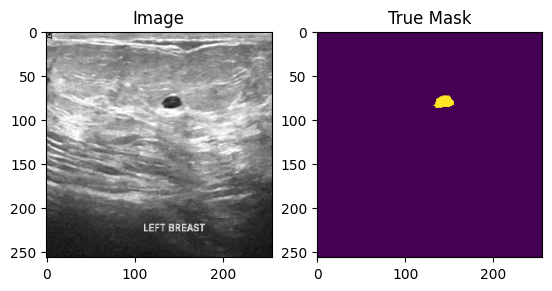

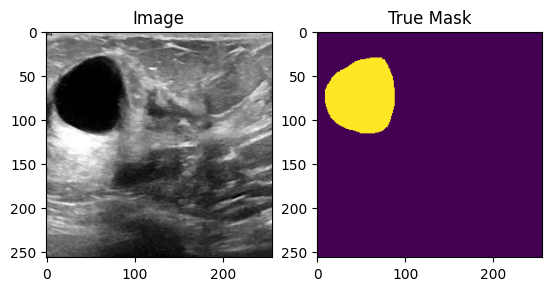

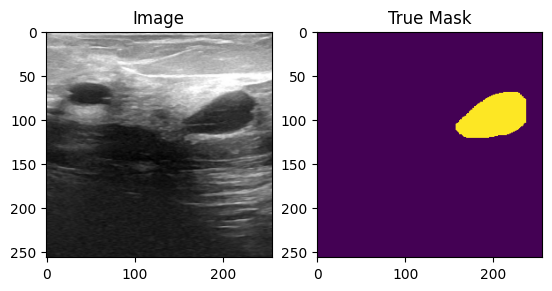

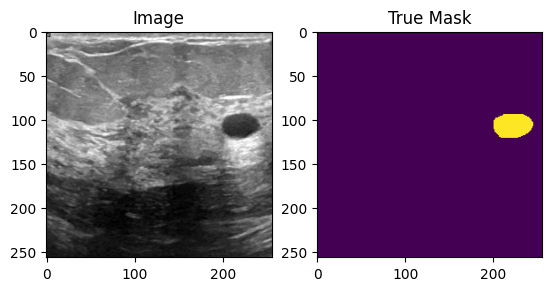

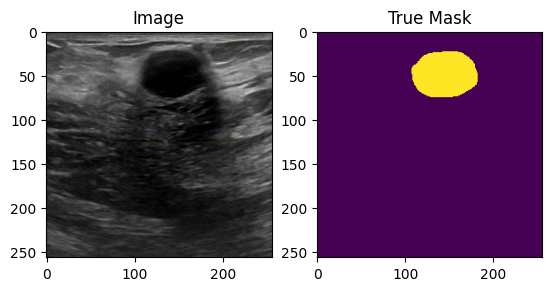

In [ ]:
for i in range(5):
    image = benign_images[i]
    mask = benign_masks[i]

    # Display the image and the true mask
    fig, (ax1, ax2) = plt.subplots(1, 2)
    ax1.imshow(image)
    ax1.set_title("Image")
    ax2.imshow(mask)
    ax2.set_title("True Mask")

    plt.show()

# Defining and Fitting Model

In [ ]:
def create_upsample_layer(filters, kernel_size, padding='same', kernel_initializer='he_normal'):
    """ This function creates a layer that upsamples an input tensor using a convolutional, batch
    normalization, and ReLU activation, followed by an upsampling operation. """
    def layer(x):
        x = Conv2D(filters, kernel_size, padding=padding, kernel_initializer=kernel_initializer)(x)
        x = BatchNormalization()(x)
        x = ReLU()(x)
        x = UpSampling2D(size=(2, 2))(x)
        return x
    return layer

def create_downsample_layer(filters, kernel_size, padding='same', kernel_initializer='he_normal'):
    """ This function creates a layer that downsamples an input tensor using a convolutional, batch
    normalization, and ReLU activation, followed by a max pooling operation. """
    def layer(x):
        x = Conv2D(filters, kernel_size, padding=padding, kernel_initializer=kernel_initializer)(x)
        x = BatchNormalization()(x)
        x = ReLU()(x)
        x = MaxPool2D(pool_size=(2, 2))(x)
        return x
    return layer

dropout_rate = 0.15

# Example usage
inputs = Input(shape=(256, 256, 3))
# Encoder part of the DeepUNet
x = create_downsample_layer(64, 3, padding='same', kernel_initializer='he_normal')(inputs)
x = create_downsample_layer(128, 3, padding='same', kernel_initializer='he_normal')(x)
x = Dropout(dropout_rate)(x)
x = create_downsample_layer(256, 3, padding='same', kernel_initializer='he_normal')(x)
x = Dropout(dropout_rate)(x)
x = create_downsample_layer(512, 3, padding='same', kernel_initializer='he_normal')(x)
x = Dropout(dropout_rate)(x)
x = create_downsample_layer(1024, 3, padding='same', kernel_initializer='he_normal')(x)
x = Dropout(dropout_rate)(x)
x = create_downsample_layer(2048, 3, padding='same', kernel_initializer='he_normal')(x)
x = Dropout(dropout_rate)(x)

# Decoder part of the DeepUNet
x = create_upsample_layer(1024, 3, padding='same', kernel_initializer='he_normal')(x)
x = Dropout(dropout_rate)(x)
x = create_upsample_layer(512, 3, padding='same', kernel_initializer='he_normal')(x)
x = Dropout(dropout_rate)(x)
x = create_upsample_layer(256, 3, padding='same', kernel_initializer='he_normal')(x)
x = Dropout(dropout_rate)(x)
x = create_upsample_layer(128, 3, padding='same', kernel_initializer='he_normal')(x)
x = Dropout(dropout_rate)(x)
x = create_upsample_layer(64, 3, padding='same', kernel_initializer='he_normal')(x)
x = Dropout(dropout_rate)(x)
x = create_upsample_layer(32, 3, padding='same', kernel_initializer='he_normal')(x)
outputs = Conv2D(1, 1, padding = 'same', activation='sigmoid')(x)

model = Model(inputs=inputs, outputs=outputs)


In [ ]:
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 256, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 256, 256, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 128, 128, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 64, 64, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 32, 32, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 1024)   │     4,719,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 1024)   │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 50,332,929 (192.00 MB)

 Trainable params: 50,320,833 (191.96 MB)

 Non-trainable params: 12,096 (47.25 KB)

In [ ]:
# Define early stopping and reduce learning rate on plateau callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=20, verbose=1,
                           mode='auto', restore_best_weights=True)

reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=10,
                              verbose=1, mode='auto')

In [ ]:
def dice_loss(y_true, y_pred):
    # Flatten the predictions and ground truth
    y_true_flat = tf.reshape(y_true, [-1])
    y_pred_flat = tf.reshape(y_pred, [-1])

    # Compute the intersection and union
    intersection = tf.reduce_sum(y_true_flat * y_pred_flat)
    union = tf.reduce_sum(y_true_flat) + tf.reduce_sum(y_pred_flat)

    # Compute the Dice loss
    dice_loss = 1 - 2 * intersection / union

    return dice_loss

# Compile the model with the Dice loss
model.compile(loss=dice_loss, optimizer='adam', metrics=['accuracy'])

In [ ]:
# Define the number of epochs and the batch size
num_epochs = 50
batch_size = 16

# Set seed
# tf.random.set_seed(42)
tf.random.set_seed(1)

# Train the UNet model on the training data
history = model.fit(#dataset,
                    train_images,
                    train_masks,
                    batch_size=batch_size, epochs=num_epochs,
                    callbacks=[early_stop, reduce_lr],
                    validation_data=(val_images, val_masks))


Epoch 1/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 106s 1s/step - accuracy: 0.7657 - loss: 0.7079 - val_accuracy: 0.0959 - val_loss: 0.8646 - learning_rate: 0.0010
Epoch 2/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 9s 211ms/step - accuracy: 0.8889 - loss: 0.6081 - val_accuracy: 0.4772 - val_loss: 0.8356 - learning_rate: 0.0010
Epoch 3/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 9s 211ms/step - accuracy: 0.9243 - loss: 0.5082 - val_accuracy: 0.6134 - val_loss: 0.7790 - learning_rate: 0.0010
Epoch 4/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 9s 211ms/step - accuracy: 0.9389 - loss: 0.4325 - val_accuracy: 0.6151 - val_loss: 0.7627 - learning_rate: 0.0010
Epoch 5/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 9s 214ms/step - accuracy: 0.9447 - loss: 0.3896 - val_accuracy: 0.7877 - val_loss: 0.6771 - learning_rate: 0.0010
Epoch 6/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 9s 212ms/step - accuracy: 0.9521 - loss: 0.3403 - val_accuracy: 0.9356 - val_loss: 0.5238 - learning_rate: 0.0010
Epoch 7/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 9s 214ms/step - accuracy: 0.9515 - loss: 0.3350 - v

# Visualizing Model Performance and Predictions

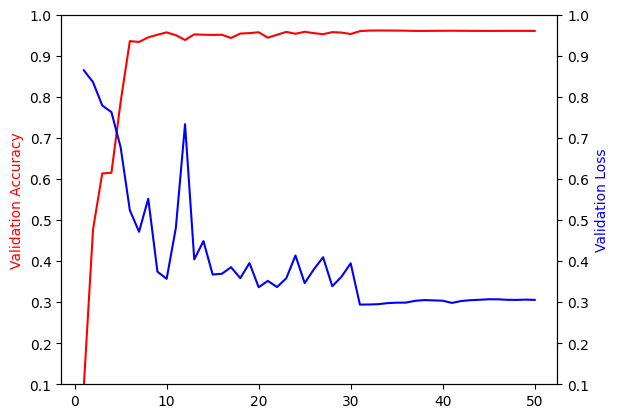

In [ ]:
# Epochs and corresponding val_loss and val_accuracy values
epochs_list = list(range(1, len(history.history['val_loss']) + 1))
val_loss = history.history['val_loss']
val_accuracy = history.history['val_accuracy']

# Plot the epoch vs val_loss
ax1 = plt.subplot(111)
ax1.plot(epochs_list, val_accuracy, 'r-')
ax1.set_ylabel('Validation Accuracy', color='r')

# Create a second y-axis for the val_accuracy
ax2 = ax1.twinx()
ax2.plot(epochs_list, val_loss, 'b-')
ax2.set_ylabel('Validation Loss', color='b')

# Set the same scaling on the y-axes
ax1.set_ylim([0.1, 1])
ax2.set_ylim([0.1, 1])

plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


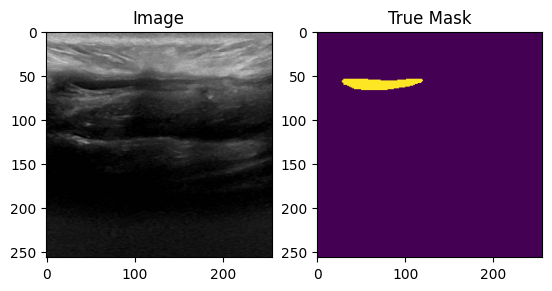

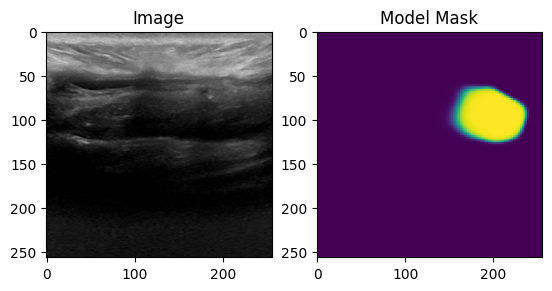

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


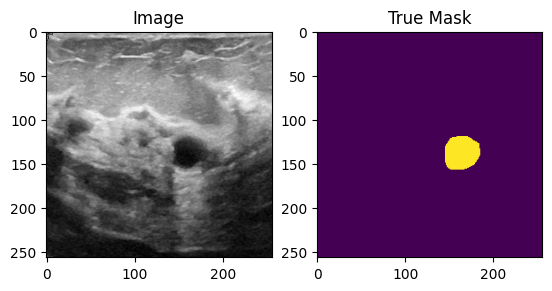

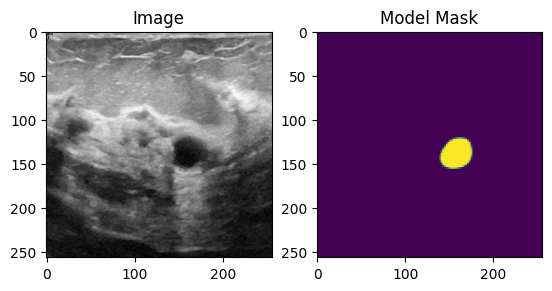

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


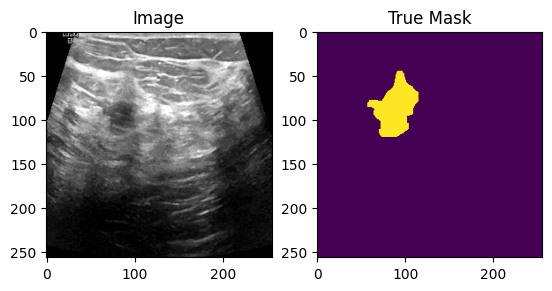

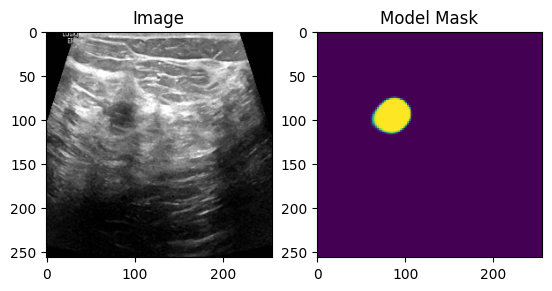

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


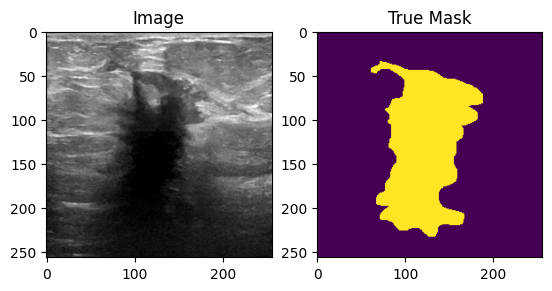

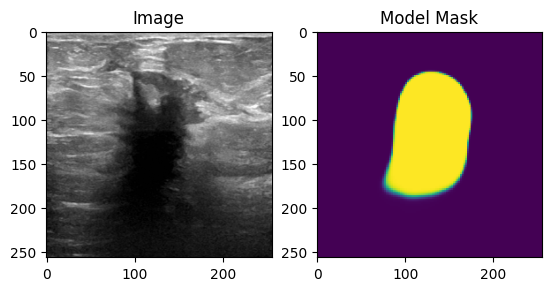

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


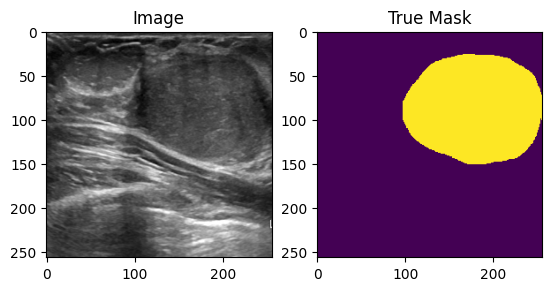

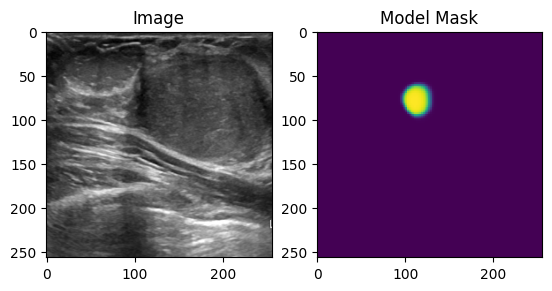

In [ ]:
for i in range(5):
    # Select an image and its true mask
    image = test_images[i]
    mask = test_masks[i]

    # Make a prediction using the model
    prediction = model.predict(image[None, ...])[0]

    # Display the image and the true mask
    fig, (ax1, ax2) = plt.subplots(1, 2)
    ax1.imshow(image)
    ax1.set_title("Image")
    ax2.imshow(mask)
    ax2.set_title("True Mask")

    # Display the image and the model's prediction
    fig, (ax1, ax2) = plt.subplots(1, 2)
    ax1.imshow(image)
    ax1.set_title("Image")
    ax2.imshow(prediction)
    ax2.set_title("Model Mask")

    plt.show()


There are a few reasons why the model might perform poorly on images without cancer. One reason is that it simply hasn't been trained on enough examples of these types of images. This means that the model doesn't have enough information to accurately classify these images. Another reason could be that the model is overfitting to the images that do contain cancer, and is therefore not able to generalize well to images without cancer.

One way to improve the performance on images without cancer would be to set a lower bound on the image segmentation. This would help the model to more accurately identify areas of the image that are likely to contain cancer, and would therefore improve its performance on images without cancer.

This project could be revisited in the future to set a lower bound on the image segmentation and add more non-cancerous images/masks to see if it leads to improved performance on images without cancer.

# Model Metrics

In [ ]:
predictions = model.predict(test_images)

# If predictions are probabilities, convert them to binary masks
predictions_binary = (predictions > 0.5).astype(np.float32)

# Compute the mean IoU metric on the test set
mean_iou = tf.keras.metrics.MeanIoU(num_classes=2)
mean_iou.update_state(test_masks, predictions_binary)
print("Mean IoU on test set: {:.3f}".format(mean_iou.result()))

# Compute the precision and recall on the test set
precision = tf.keras.metrics.Precision()
recall = tf.keras.metrics.Recall()

precision.update_state(test_masks, predictions_binary)
recall.update_state(test_masks, predictions_binary)

precision_value = precision.result()
recall_value = recall.result()

# Compute the F1 score
f1_score = 2 * (precision_value * recall_value) / (precision_value + recall_value + tf.keras.backend.epsilon())
print("F1 score on test set: {:.3f}".format(f1_score))

# Compute Dice coefficient
y_true = tf.cast(test_masks, tf.float32)
# Expand dimensions of y_true to match y_pred (batch, height, width, 1)
y_true = tf.expand_dims(y_true, axis=-1)
y_pred = tf.cast(predictions_binary, tf.float32)

intersection = tf.reduce_sum(y_true * y_pred)
dice_coefficient = (2.0 * intersection + tf.keras.backend.epsilon()) / (
    tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + tf.keras.backend.epsilon()
)

print("Dice coefficient on test set: {:.3f}".format(dice_coefficient))

# Reset the metrics
mean_iou.reset_state()
precision.reset_state()
recall.reset_state()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
Mean IoU on test set: 0.752
F1 score on test set: 0.717
Dice coefficient on test set: 0.717


Overall the F1 score is good but I hope to tune the model in the future